# Superseded analyses

Earlier analyses and figure versions from the working notebook, kept for the record. None of them is used in the paper or the supplementary material; each section names the analysis in `headpose_fatigue_grouped_evaluation.ipynb` that replaced it.

The code is kept exactly as it was run, with its saved outputs. It reads result files by the names they had in the original working folder, which differ from the names in `results/`, so these cells are not meant to be run again. Older names used here: random split or subject dependent baseline (now the random-frame split, or the random-window split for the Bi-LSTM), corrected protocol or subject based split (now subject held out), video based split (now recording held out), Eye + Head Pose (now EAR + Head Pose) and Full Set (EAR+MAR+Pose) (now Full Set).

## Setup used by these cells
The configuration, imports, plot style and plotting helpers of the working notebook. `DATA_DIR` pointed to the original working folder.

In [ ]:
import os
DATA_DIR = "."
assert os.path.isdir(DATA_DIR), f"DATA_DIR not found: {DATA_DIR}"
TEST_SUBJECTS = {'1', '4', '7', '14', '20', '21', '42', '50', '51', '53', '55', '59'}

In [ ]:
import time
import textwrap
import joblib
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay)

In [ ]:
mpl.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.titleweight': 'bold',
    'axes.labelsize': 12,
    'axes.edgecolor': '#333333',
    'axes.linewidth': 1.0,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.axisbelow': True,
    'axes.grid': True,
    'grid.color': '#d9d9d9',
    'grid.linestyle': '--',
    'grid.linewidth': 0.6,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'legend.frameon': False,
    'figure.dpi': 150,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
})

def wrap_labels(labels, width=14):
    return ["\n".join(textwrap.wrap(l, width)) for l in labels]

def label_bars(ax, bars, fontsize=8.5):
    for bar in bars:
        h = bar.get_height()
        ax.annotate(f'{h:.1f}', (bar.get_x() + bar.get_width()/2, h), xytext=(0, 3),
                    textcoords='offset points', ha='center', fontsize=fontsize)

## Earlier figure versions

### Bi-LSTM accuracy curves for the Full Set and EAR + MAR
Training and validation accuracy per epoch. Replaced by the loss curves in section 7.3 of the main notebook.

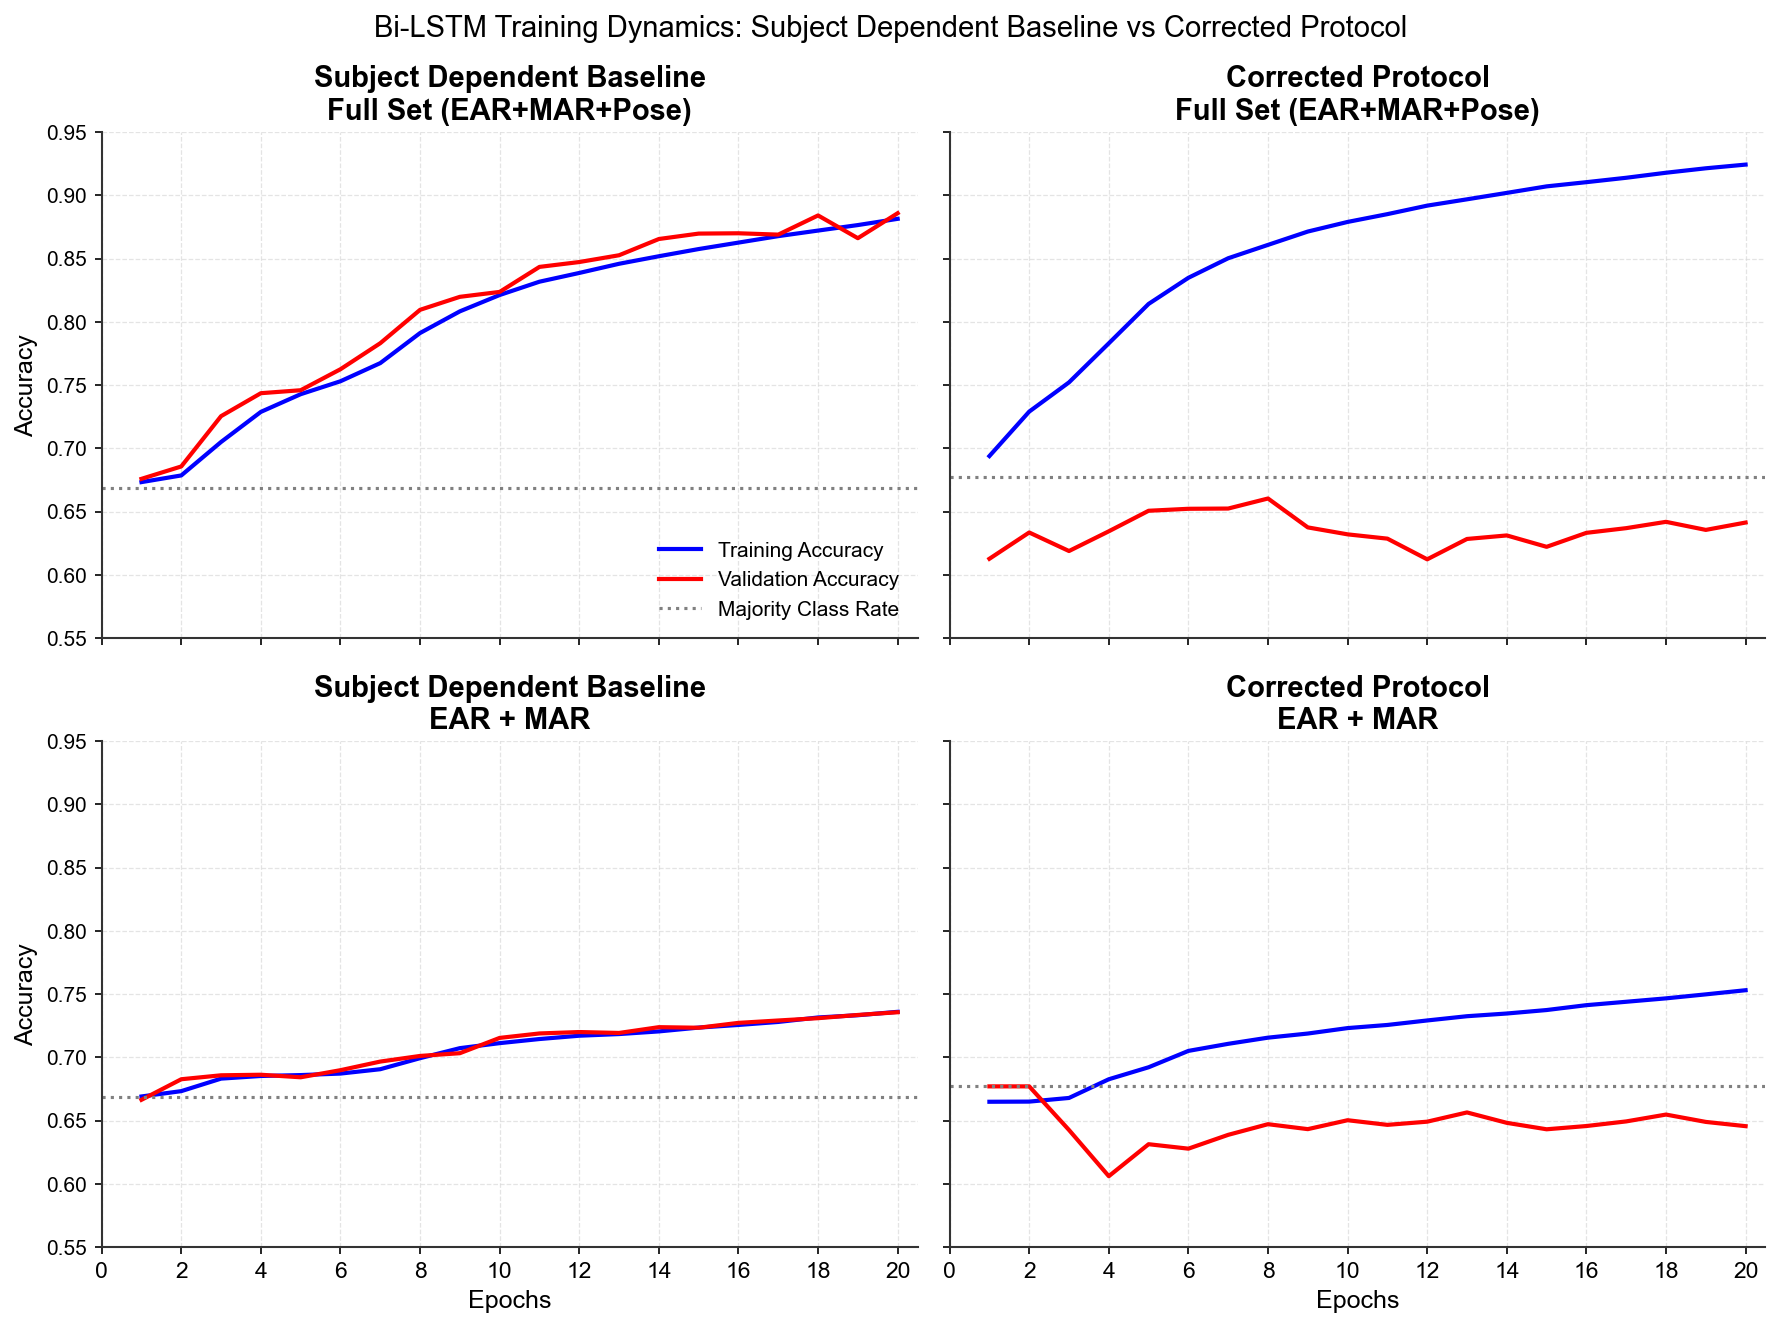

In [55]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

path_base_full = os.path.join(DATA_DIR, "lstm_baseline_full_set_earmarpose_history.csv")
path_base_earmar = os.path.join(DATA_DIR, "lstm_baseline_ear__mar_history.csv")
path_corr_full = os.path.join(DATA_DIR, "lstm_full_set_history.csv")
path_corr_earmar = os.path.join(DATA_DIR, "lstm_ear__mar_history.csv")

for p in (path_base_full, path_base_earmar, path_corr_full, path_corr_earmar):
    if not os.path.exists(p):
        raise FileNotFoundError(f"Missing history file: {p}")

prior_baseline = np.load(os.path.join(DATA_DIR, "y_baseline.npy")).mean()
prior_corrected = np.load(os.path.join(DATA_DIR, "y_val.npy")).mean()

panels = [
    [(path_base_full, prior_baseline, "Subject Dependent Baseline\nFull Set (EAR+MAR+Pose)"),
     (path_corr_full, prior_corrected, "Corrected Protocol\nFull Set (EAR+MAR+Pose)")],
    [(path_base_earmar, prior_baseline, "Subject Dependent Baseline\nEAR + MAR"),
     (path_corr_earmar, prior_corrected, "Corrected Protocol\nEAR + MAR")],
]

Y_MIN, Y_MAX = 0.55, 0.95

fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharex=True, sharey=True)
for r in range(2):
    for c in range(2):
        path, prior, title = panels[r][c]
        ax = axes[r, c]
        hist = pd.read_csv(path)
        epochs = range(1, len(hist) + 1)
        ax.plot(epochs, hist['accuracy'], label='Training Accuracy', color='blue', lw=2)
        ax.plot(epochs, hist['val_accuracy'], label='Validation Accuracy', color='red', lw=2)
        ax.axhline(prior, color='gray', linestyle=':', linewidth=1.5, label='Majority Class Rate')
        ax.set_title(title)
        ax.set_xlim(0, 20.5)
        ax.set_xticks(range(0, 21, 2))
        ax.set_ylim(Y_MIN, Y_MAX)
        ax.set_yticks([round(Y_MIN + 0.05 * i, 2) for i in range(int(round((Y_MAX - Y_MIN) / 0.05)) + 1)])
        ax.grid(True, linestyle='--', alpha=0.7)
        if r == 1:
            ax.set_xlabel('Epochs')
        if c == 0:
            ax.set_ylabel('Accuracy')
axes[0, 0].legend(loc='lower right')

plt.suptitle('Bi-LSTM Training Dynamics: Subject Dependent Baseline vs Corrected Protocol', fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(DATA_DIR, "learning_curve_comparison.png"), dpi=300, bbox_inches='tight')
plt.show()

### Bi-LSTM accuracy curves for the remaining feature sets
Replaced by the loss curves in section 7.4 of the main notebook.

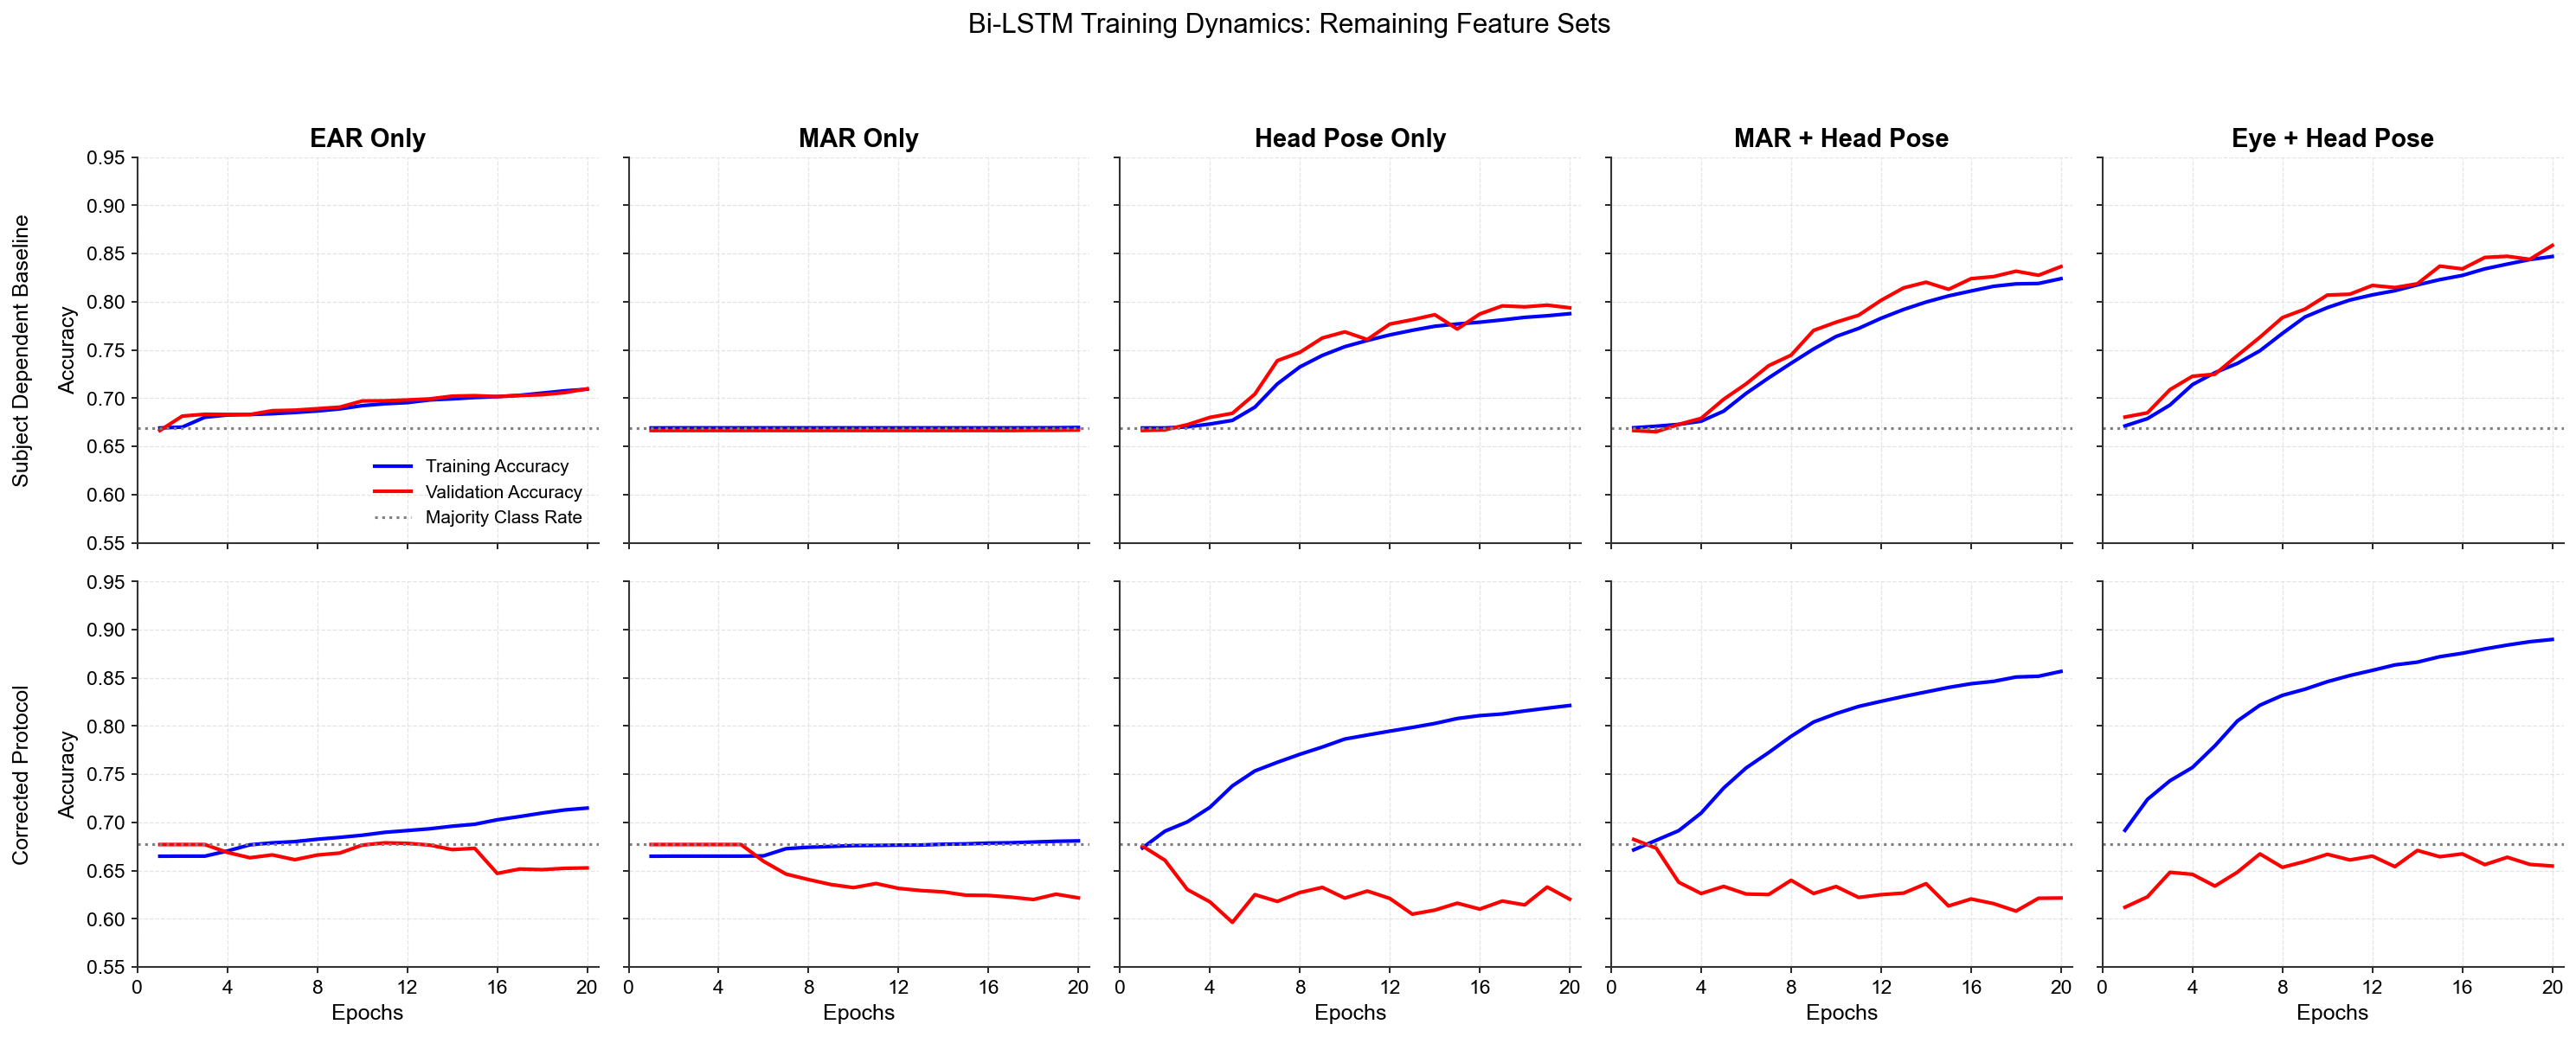

In [64]:
feature_sets = ["EAR Only", "MAR Only", "Head Pose Only", "MAR + Head Pose", "Eye + Head Pose"]

def safe(name):
    return name.lower().replace(" ", "_").replace("(", "").replace(")", "").replace("+", "")

prior_baseline = np.load(os.path.join(DATA_DIR, "y_baseline.npy")).mean()
prior_corrected = np.load(os.path.join(DATA_DIR, "y_val.npy")).mean()

protocols = [("lstm_baseline_", prior_baseline, "Subject Dependent Baseline"),
             ("lstm_", prior_corrected, "Corrected Protocol")]

Y_MIN, Y_MAX = 0.55, 0.95

fig, axes = plt.subplots(2, len(feature_sets), figsize=(20, 8), sharex=True, sharey=True)
for r, (prefix, prior, protocol) in enumerate(protocols):
    for c, name in enumerate(feature_sets):
        path = os.path.join(DATA_DIR, f"{prefix}{safe(name)}_history.csv")
        if not os.path.exists(path):
            raise FileNotFoundError(f"Missing history file: {path}")
        hist = pd.read_csv(path)
        epochs = range(1, len(hist) + 1)
        ax = axes[r, c]
        ax.plot(epochs, hist['accuracy'], label='Training Accuracy', color='blue', lw=2)
        ax.plot(epochs, hist['val_accuracy'], label='Validation Accuracy', color='red', lw=2)
        ax.axhline(prior, color='gray', linestyle=':', linewidth=1.5, label='Majority Class Rate')
        ax.set_xlim(0, 20.5)
        ax.set_xticks(range(0, 21, 4))
        ax.set_ylim(Y_MIN, Y_MAX)
        ax.set_yticks([round(Y_MIN + 0.05 * i, 2) for i in range(int(round((Y_MAX - Y_MIN) / 0.05)) + 1)])
        ax.grid(True, linestyle='--', alpha=0.7)
        ax.tick_params(labelsize=11)
        if r == 0:
            ax.set_title(name, fontsize=14)
        if r == 1:
            ax.set_xlabel('Epochs', fontsize=12)
        if c == 0:
            ax.set_ylabel(f"{protocol}\n\nAccuracy", fontsize=12)
axes[0, 0].legend(loc='lower right', fontsize=10)

plt.suptitle('Bi-LSTM Training Dynamics: Remaining Feature Sets', fontsize=15, y=0.995)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig(os.path.join(DATA_DIR, "learning_curve_other_feature_sets.png"), dpi=300, bbox_inches='tight')
plt.show()

### Random Forest and Bi-LSTM balanced accuracy by feature set
Replaced by the comparison of all five models in section 7.5 of the main notebook.

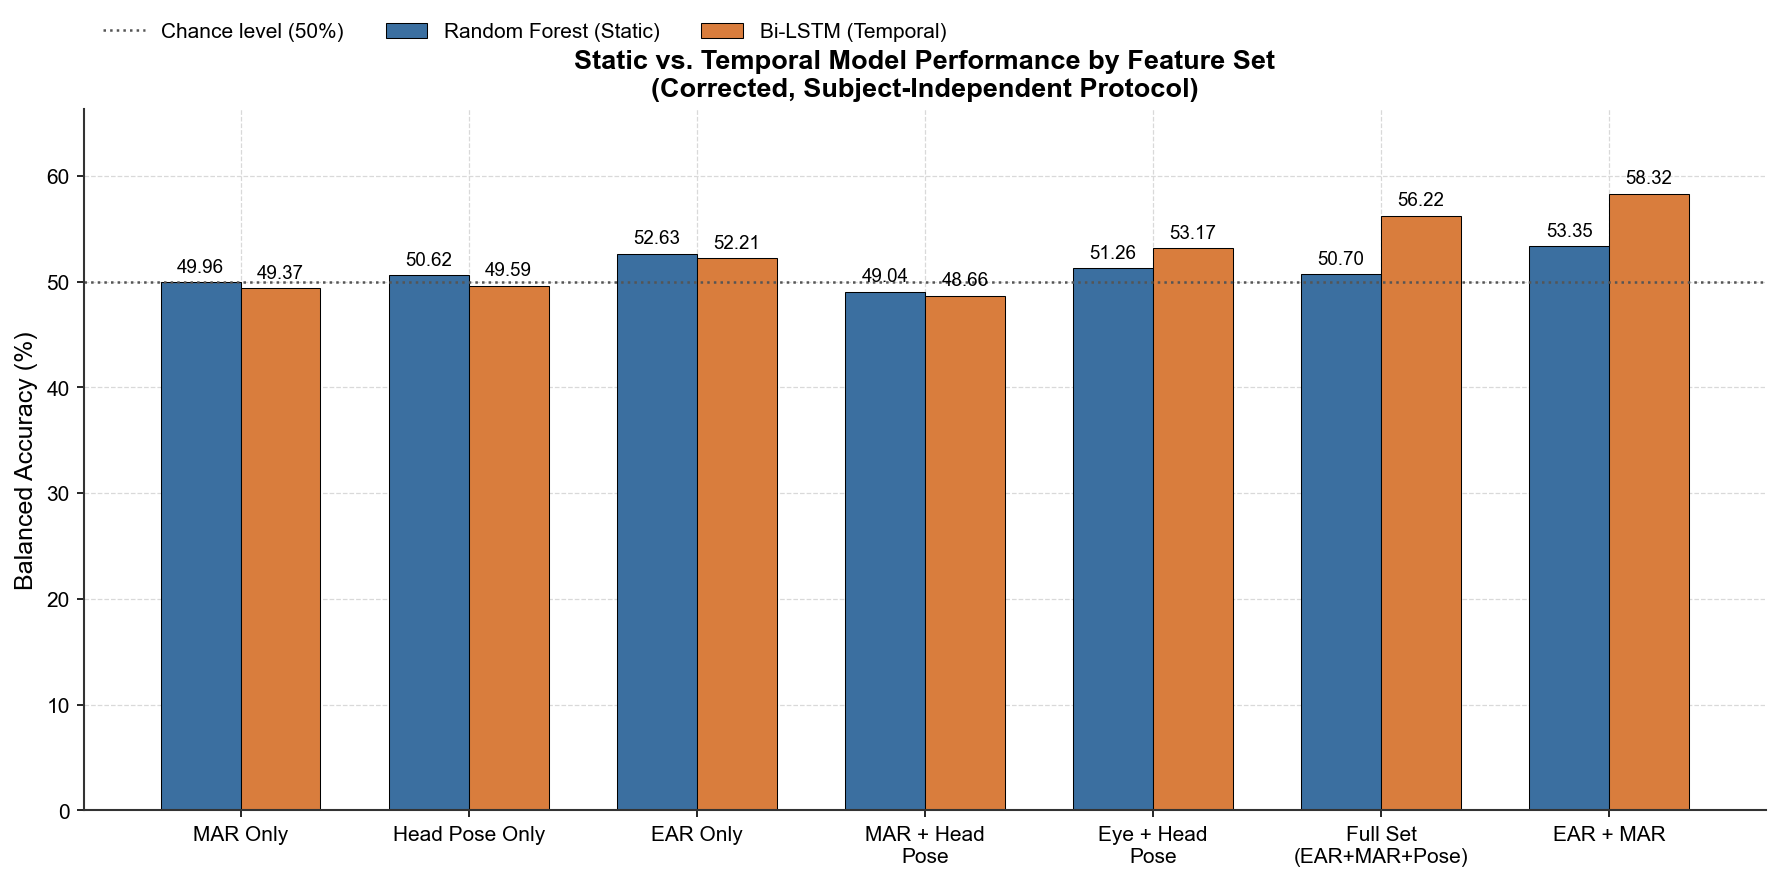

In [63]:
rf_data = pd.read_csv(os.path.join(DATA_DIR, "full_static_results_experimentA.csv"))
rf_data = rf_data[rf_data["Classifier"] == "Random Forest"].set_index("Feature Set")
lstm_data = pd.read_csv(os.path.join(DATA_DIR, "lstm_ablation_results_grouped.csv")).set_index("Feature Set")

order = ["MAR Only", "Head Pose Only", "EAR Only", "MAR + Head Pose",
         "Eye + Head Pose", "Full Set (EAR+MAR+Pose)", "EAR + MAR"]

rf_vals = [rf_data.loc[f, "Balanced Accuracy"] * 100 for f in order]
lstm_vals = [lstm_data.loc[f, "Balanced Accuracy"] * 100 for f in order]

x = np.arange(len(order))
width = 0.35
fig, ax = plt.subplots(figsize=(12, 6))

b1 = ax.bar(x - width/2, rf_vals, width, label="Random Forest (Static)",
            color="#3B6FA0", edgecolor="black", linewidth=0.5)
b2 = ax.bar(x + width/2, lstm_vals, width, label="Bi-LSTM (Temporal)",
            color="#D97D3D", edgecolor="black", linewidth=0.5)

ax.bar_label(b1, fmt="%.2f", padding=3, fontsize=9)
ax.bar_label(b2, fmt="%.2f", padding=3, fontsize=9)
ax.axhline(50, color="#555555", linestyle=":", linewidth=1.2,
           label="Chance level (50%)")

ax.set_xticks(x)
ax.set_xticklabels(wrap_labels(order, 14), rotation=0, ha="center")
ax.set_ylabel("Balanced Accuracy (%)")
ax.set_ylim(0, max(max(rf_vals), max(lstm_vals)) + 8)
ax.set_title("Static vs. Temporal Model Performance by Feature Set\n"
             "(Corrected, Subject-Independent Protocol)")
ax.legend(loc="upper left", ncol=3, bbox_to_anchor=(0, 1.15))

plt.tight_layout()
plt.savefig(os.path.join(DATA_DIR, "fig3_static_vs_temporal_corrected.png"),
            dpi=300, bbox_inches="tight")
plt.show()

### Confusion matrices for EAR + MAR
Random Forest and Bi-LSTM with EAR + MAR on the held-out drivers. Not reported in the paper.

Random Forest (EAR + MAR): {'Accuracy': 0.6189, 'Balanced Accuracy': 0.5335, 'Drowsy Recall': 0.7783, 'Alert Recall': 0.2887}
Bi-LSTM (EAR + MAR):       {'Accuracy': 0.6758, 'Balanced Accuracy': 0.5832, 'Drowsy Recall': 0.8486, 'Alert Recall': 0.3178}
Bi-LSTM test windows: 133468 | predicted Drowsy: 106028 | predicted Alert: 27440


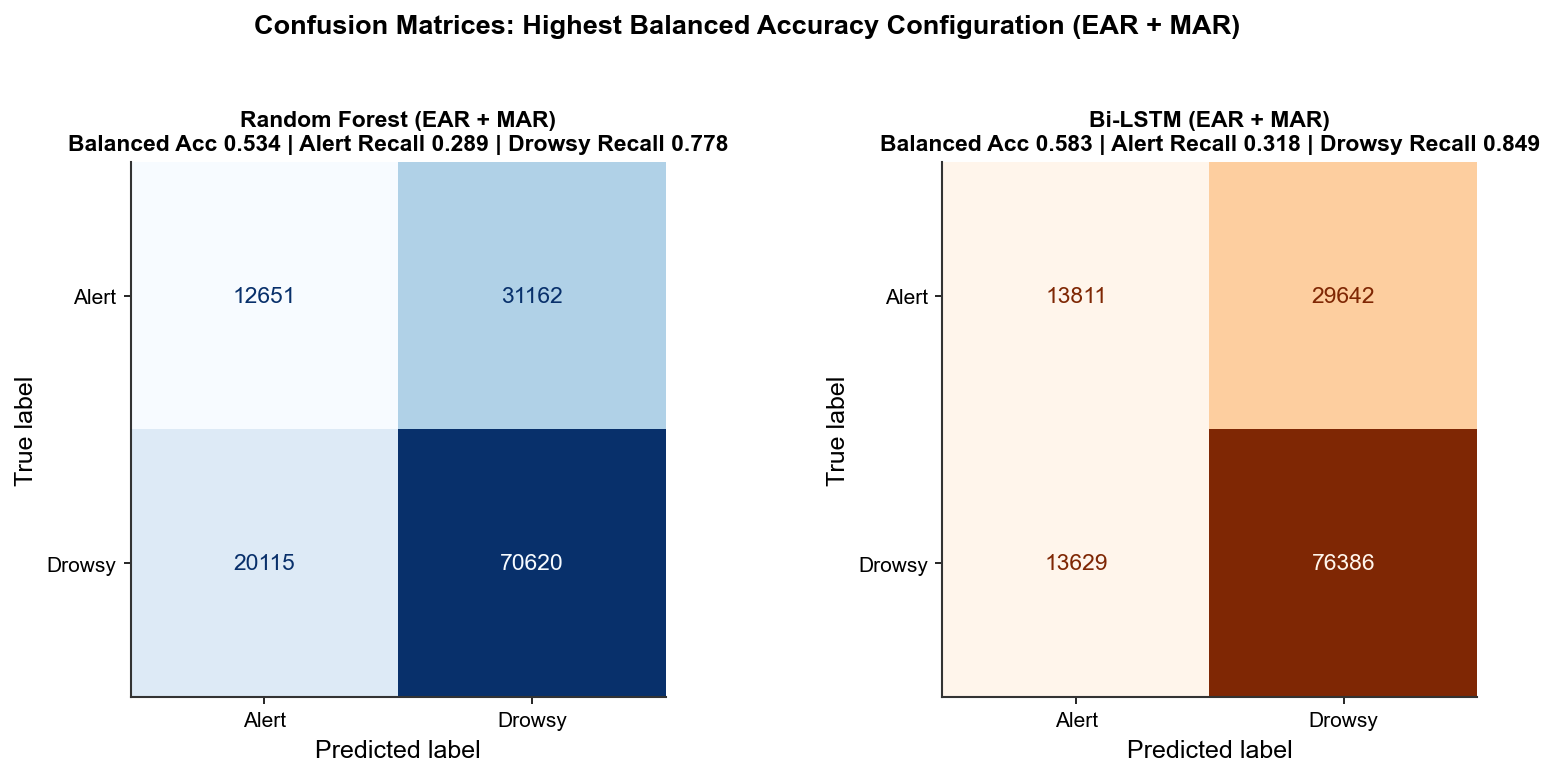

In [65]:
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             balanced_accuracy_score, recall_score, accuracy_score)

# Random Forest (EAR + MAR), corrected protocol, Experiment A
rf_preds = pd.read_csv(os.path.join(DATA_DIR, "random_forest_ear_mar_preds_experimentA.csv"))["pred"].values
df_uta = pd.read_csv(os.path.join(DATA_DIR, "uta_complete_results_pose.csv"))
df_uta['Target'] = df_uta['Video_ID'].apply(lambda x: 1 if ('_10' in str(x) or '_5' in str(x)) else 0)
df_uta['Subject'] = df_uta['Video_ID'].str.split('_').str[0]
y_test_rf = df_uta[df_uta['Subject'].isin(TEST_SUBJECTS)]['Target'].values
assert len(rf_preds) == len(y_test_rf), "RF predictions and labels have different lengths"

lstm_preds = np.load(os.path.join(DATA_DIR, "lstm_ear__mar_preds.npy")).ravel()
lstm_preds = (lstm_preds > 0.5).astype(int)
y_test_lstm = np.load(os.path.join(DATA_DIR, "y_test_full.npy")).ravel()
assert len(lstm_preds) == len(y_test_lstm), "LSTM predictions and labels have different lengths"

def summarize(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "Drowsy Recall": recall_score(y_true, y_pred),
        "Alert Recall": recall_score(y_true, y_pred, pos_label=0),
    }

rf_s = summarize(y_test_rf, rf_preds)
lstm_s = summarize(y_test_lstm, lstm_preds)
print("Random Forest (EAR + MAR):", {k: round(v, 4) for k, v in rf_s.items()})
print("Bi-LSTM (EAR + MAR):      ", {k: round(v, 4) for k, v in lstm_s.items()})
print("Bi-LSTM test windows:", len(y_test_lstm), "| predicted Drowsy:", int(lstm_preds.sum()),
      "| predicted Alert:", int((lstm_preds == 0).sum()))

def panel_title(name, s):
    return (f"{name}\nBalanced Acc {s['Balanced Accuracy']:.3f} | "
            f"Alert Recall {s['Alert Recall']:.3f} | Drowsy Recall {s['Drowsy Recall']:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test_rf, rf_preds),
                       display_labels=['Alert', 'Drowsy']).plot(
    cmap='Blues', ax=axes[0], colorbar=False, values_format='d')
axes[0].set_title(panel_title("Random Forest (EAR + MAR)", rf_s), fontsize=11)
ConfusionMatrixDisplay(confusion_matrix(y_test_lstm, lstm_preds),
                       display_labels=['Alert', 'Drowsy']).plot(
    cmap='Oranges', ax=axes[1], colorbar=False, values_format='d')
axes[1].set_title(panel_title("Bi-LSTM (EAR + MAR)", lstm_s), fontsize=11)
for ax in axes:
    ax.grid(False)
plt.suptitle("Confusion Matrices: Highest Balanced Accuracy Configuration (EAR + MAR)",
             fontweight='bold', fontsize=13, y=1.03)
plt.tight_layout()
plt.savefig(os.path.join(DATA_DIR, "confusion_ear_mar_corrected.png"), dpi=300, bbox_inches="tight")
plt.show()

### Random Forest accuracy and balanced accuracy before and after the split correction
Replaced by the drop heatmap in section 7.1 of the main notebook.

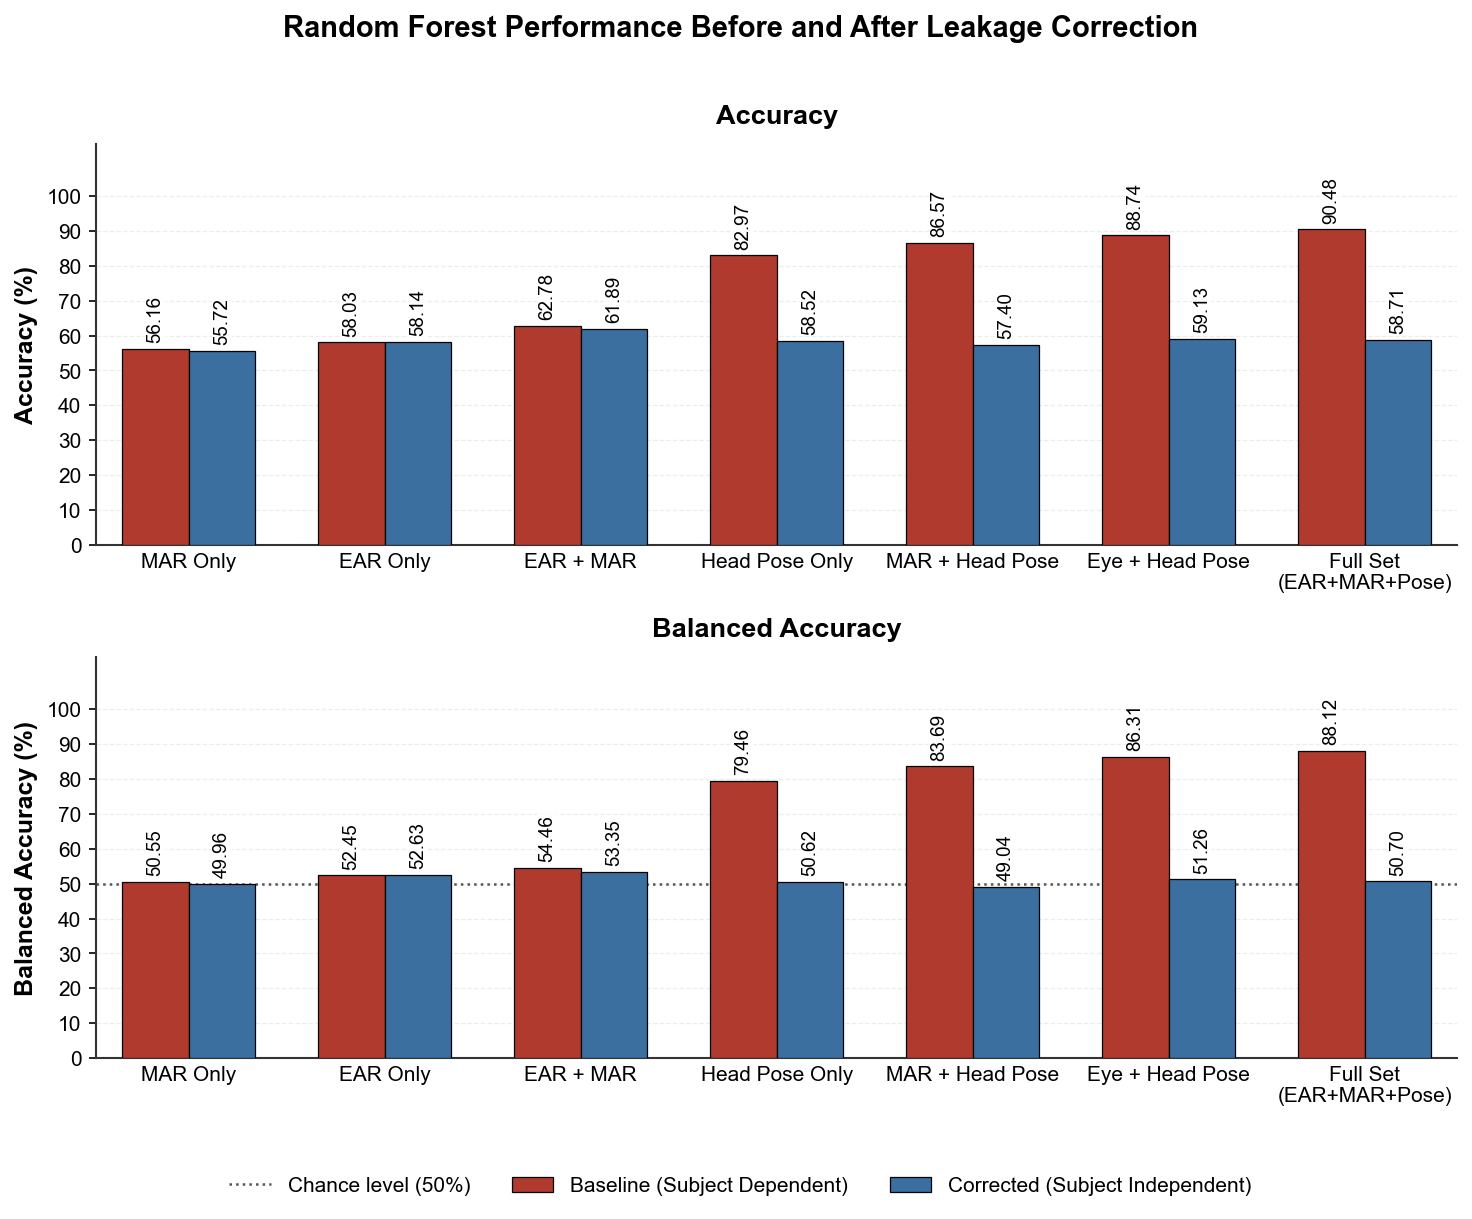

In [68]:
corrected = pd.read_csv(os.path.join(DATA_DIR, "full_static_results_experimentA.csv"))
baseline = pd.read_csv(os.path.join(DATA_DIR, "static_ablation_results_baseline_uta_ba.csv"))

for name, df in [("corrected", corrected), ("baseline", baseline)]:
    missing = [c for c in ["Classifier", "Feature Set", "Accuracy", "Balanced Accuracy"] if c not in df.columns]
    if missing:
        raise KeyError(f"{name} file is missing {missing}. Columns found: {list(df.columns)}")

rf_corrected = corrected[corrected["Classifier"] == "Random Forest"].set_index("Feature Set")
rf_baseline = baseline[baseline["Classifier"] == "Random Forest"].set_index("Feature Set")

order = ["MAR Only", "EAR Only", "EAR + MAR", "Head Pose Only",
         "MAR + Head Pose", "Eye + Head Pose", "Full Set (EAR+MAR+Pose)"]

plt.rcParams.update({
    "font.family": "Arial", "font.size": 11, "axes.titlesize": 13,
    "axes.labelsize": 12, "xtick.labelsize": 10, "ytick.labelsize": 10, "legend.fontsize": 10
})

x = np.arange(len(order))
width = 0.34
fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharey=True)

for ax, metric, title in zip(axes, ["Accuracy", "Balanced Accuracy"],
                             ["Accuracy", "Balanced Accuracy"]):
    base_vals = [rf_baseline.loc[f, metric] * 100 for f in order]
    corr_vals = [rf_corrected.loc[f, metric] * 100 for f in order]

    b1 = ax.bar(x - width/2, base_vals, width, label="Baseline (Subject Dependent)",
                color="#B03A2E", edgecolor="black", linewidth=0.6, zorder=3)
    b2 = ax.bar(x + width/2, corr_vals, width, label="Corrected (Subject Independent)",
                color="#3B6FA0", edgecolor="black", linewidth=0.6, zorder=3)

    for bars, vals in [(b1, base_vals), (b2, corr_vals)]:
        for t in ax.bar_label(bars, labels=[f"{v:.2f}" for v in vals], padding=3, fontsize=9, rotation=90):
            t.set_bbox(dict(facecolor="white", edgecolor="none", pad=0.6, alpha=0.85))

    if metric == "Balanced Accuracy":
        ax.axhline(50, color="#555555", linestyle=":", linewidth=1.2, label="Chance level (50%)", zorder=2)

    ax.set_xticks(x)
    ax.set_xticklabels(wrap_labels(order, 15), ha="center", linespacing=1.15)
    ax.set_ylabel(f"{metric} (%)", fontweight="bold")
    ax.set_title(title, fontweight="bold", pad=10)
    ax.set_ylim(0, 115)
    ax.set_yticks(np.arange(0, 101, 10))
    ax.grid(axis="y", linestyle="--", linewidth=0.6, alpha=0.45, zorder=0)
    ax.xaxis.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(axis="x", length=0)
    ax.margins(x=0.02)

handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.02))
fig.suptitle("Random Forest Performance Before and After Leakage Correction",
             fontweight="bold", fontsize=14)
plt.tight_layout(rect=[0, 0.05, 1, 0.97])
plt.savefig(os.path.join(DATA_DIR, "fig7_headpose_leakage_rf.png"), dpi=600, bbox_inches="tight", facecolor="white")
plt.savefig(os.path.join(DATA_DIR, "fig7_headpose_leakage_rf.pdf"), bbox_inches="tight", facecolor="white")
plt.show()

### Drop heatmap for the static classifiers
Earlier version without the Bi-LSTM column. Replaced by section 7.1 of the main notebook.

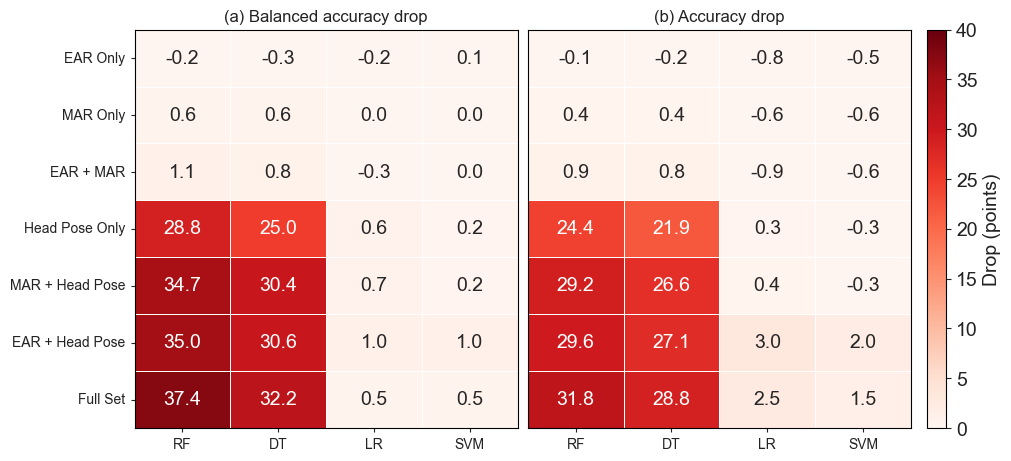

In [14]:
corrected = pd.read_csv(os.path.join(DATA_DIR, "full_static_results_experimentA.csv"))
baseline = pd.read_csv(os.path.join(DATA_DIR, "static_ablation_results_baseline_uta_ba.csv"))

order = ["EAR Only", "MAR Only", "EAR + MAR", "Head Pose Only",
         "MAR + Head Pose", "Eye + Head Pose", "Full Set (EAR+MAR+Pose)"]
classifiers = ["Random Forest", "Decision Tree", "Logistic Regression", "Linear SVM"]

feature_labels = ["EAR Only", "MAR Only", "EAR + MAR", "Head Pose Only",
                  "MAR + Head Pose", "EAR + Head Pose", "Full Set"]
classifier_labels = ["RF", "DT", "LR", "SVM"]

def drop_matrix(metric):
    m = pd.DataFrame(index=classifiers, columns=order, dtype=float)
    for clf in classifiers:
        for feat in order:
            b = baseline[(baseline["Classifier"] == clf) & (baseline["Feature Set"] == feat)][metric].values[0]
            c = corrected[(corrected["Classifier"] == clf) & (corrected["Feature Set"] == feat)][metric].values[0]
            m.loc[clf, feat] = (b - c) * 100
    return m.T

delta_ba = drop_matrix("Balanced Accuracy")
delta_acc = drop_matrix("Accuracy")

VMIN, VMAX = 0, 40
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), constrained_layout=True)

panels = [
    (axes[0], delta_ba, "(a) Balanced accuracy drop"),
    (axes[1], delta_acc, "(b) Accuracy drop"),
]
for ax, mat, title in panels:
    sns.heatmap(mat, annot=True, fmt=".1f", cmap="Reds", vmin=VMIN, vmax=VMAX,
                cbar=False, linewidths=0.5, linecolor="white", ax=ax)
    ax.set_title(title, fontsize=12)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_xticklabels(classifier_labels, rotation=0)
    ax.set_yticklabels(feature_labels, rotation=0)
    ax.tick_params(axis="both", labelsize=10, length=3)
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.8)

axes[1].tick_params(axis="y", labelleft=False, left=False)

cbar = fig.colorbar(axes[0].collections[0], ax=list(axes), fraction=0.03, pad=0.02)
cbar.set_label("Drop (points)")
cbar.set_ticks(np.arange(0, 41, 5))

plt.savefig(os.path.join(DATA_DIR, "fig9_leakage_magnitude_heatmap.png"), dpi=300, bbox_inches="tight")
plt.show()

### Random Forest impurity importance
Replaced by the comparison of impurity and permutation importance in section 7.2 of the main notebook.

Test rows: 134548 | Accuracy: 0.5871 | Balanced Accuracy: 0.5070
Yaw      0.2466
Pitch    0.2297
Roll     0.2262
EAR      0.1743
MAR      0.1232


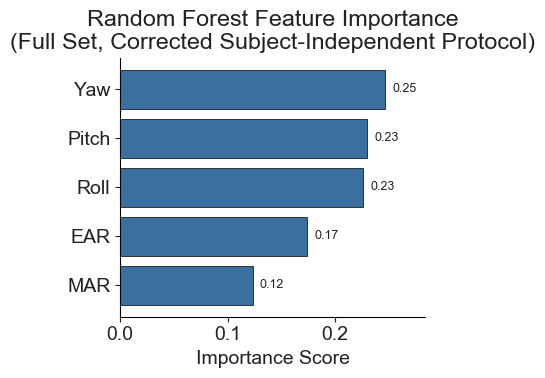

In [21]:
import os
import joblib
import pandas as pd
from sklearn.metrics import accuracy_score, balanced_accuracy_score

features = ['EAR', 'MAR', 'Pitch', 'Yaw', 'Roll']
clf = joblib.load(os.path.join(DATA_DIR, "random_forest_full_set_model.joblib"))

df_uta = pd.read_csv(os.path.join(DATA_DIR, "uta_complete_results_pose.csv"))
df_uta['Target'] = df_uta['Video_ID'].apply(lambda x: 1 if ('_10' in str(x) or '_5' in str(x)) else 0)
df_uta['Subject'] = df_uta['Video_ID'].str.split('_').str[0]
test = df_uta[df_uta['Subject'].isin(TEST_SUBJECTS)]
p = clf.predict(test[features])
print(f"Test rows: {len(test)} | Accuracy: {accuracy_score(test['Target'], p):.4f} | "
      f"Balanced Accuracy: {balanced_accuracy_score(test['Target'], p):.4f}")

feat_importances = pd.Series(clf.feature_importances_, index=features).sort_values(ascending=True)
print(feat_importances.sort_values(ascending=False).round(4).to_string())

fig, ax = plt.subplots(figsize=(4, 4))
bars = ax.barh(feat_importances.index, feat_importances.values, color="#3B6FA0", edgecolor='black', linewidth=0.5)
for bar in bars:
    w = bar.get_width()
    ax.annotate(f'{w:.2f}', (w, bar.get_y() + bar.get_height()/2), xytext=(5, 0),
                textcoords='offset points', va='center', fontsize=9)

ax.set_xlabel("Importance Score")
ax.set_title("Random Forest Feature Importance\n(Full Set, Corrected Subject-Independent Protocol)")
ax.set_xlim(0, feat_importances.max() * 1.15)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.savefig(os.path.join(DATA_DIR, "fig4_rf_feature_importance.png"), dpi=300, bbox_inches="tight")
plt.show()

### Confusion matrices for the Full Set, five models in one figure
Replaced by the two figures in section 7.6 of the main notebook.

Random Forest: Alert correct 12142 | Alert missed 31671 | Drowsy missed 23879 | Drowsy correct 66856 | balanced accuracy 0.5070
Linear SVM: Alert correct 3305 | Alert missed 40508 | Drowsy missed 6537 | Drowsy correct 84198 | balanced accuracy 0.5017
Logistic Regression: Alert correct 5969 | Alert missed 37844 | Drowsy missed 10841 | Drowsy correct 79894 | balanced accuracy 0.5084
Decision Tree: Alert correct 16148 | Alert missed 27665 | Drowsy missed 30274 | Drowsy correct 60461 | balanced accuracy 0.5175
Bi-LSTM: Alert correct 16556 | Alert missed 26897 | Drowsy missed 23107 | Drowsy correct 66908 | balanced accuracy 0.5622


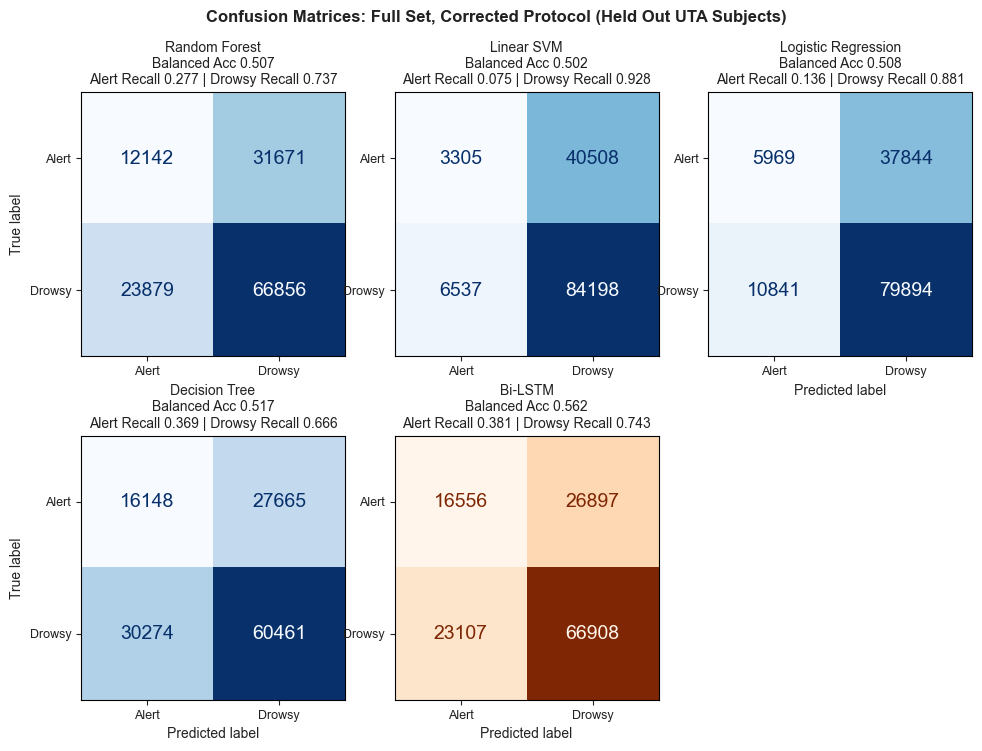

In [17]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             balanced_accuracy_score, recall_score)

features = ['EAR', 'MAR', 'Pitch', 'Yaw', 'Roll']

df_uta = pd.read_csv(os.path.join(DATA_DIR, "uta_complete_results_pose.csv"))
df_uta['Target'] = df_uta['Video_ID'].apply(lambda x: 1 if ('_10' in str(x) or '_5' in str(x)) else 0)
df_uta['Subject'] = df_uta['Video_ID'].str.split('_').str[0]
uta_test = df_uta[df_uta['Subject'].isin(TEST_SUBJECTS)]

model_files = {
    "Random Forest": "random_forest_full_set_model.joblib",
    "Linear SVM": "linear_svm_full_set_model.joblib",
    "Logistic Regression": "logistic_regression_full_set_model.joblib",
    "Decision Tree": "decision_tree_full_set_model.joblib",
}

results = {}
for name, fname in model_files.items():
    clf = joblib.load(os.path.join(DATA_DIR, fname))
    results[name] = (uta_test['Target'].values, clf.predict(uta_test[features]))

lstm_preds = np.load(os.path.join(DATA_DIR, "lstm_full_set_preds.npy")).ravel()
y_test_lstm = np.load(os.path.join(DATA_DIR, "y_test_full.npy")).ravel()
assert len(lstm_preds) == len(y_test_lstm), "Bi-LSTM predictions and labels have different lengths"
results["Bi-LSTM"] = (y_test_lstm, lstm_preds)

fig, axes = plt.subplots(2, 3, figsize=(10, 7.5))
axes = axes.flatten()

for i, (ax, (name, (y_true, y_pred))) in enumerate(zip(axes, results.items())):
    cm = confusion_matrix(y_true, y_pred)
    cmap = 'Oranges' if name == "Bi-LSTM" else 'Blues'
    ConfusionMatrixDisplay(cm, display_labels=['Alert', 'Drowsy']).plot(
        cmap=cmap, ax=ax, colorbar=False, values_format='d')
    ba = balanced_accuracy_score(y_true, y_pred)
    alert_recall = recall_score(y_true, y_pred, pos_label=0)
    drowsy_recall = recall_score(y_true, y_pred, pos_label=1)
    ax.set_title(f"{name}\nBalanced Acc {ba:.3f}\nAlert Recall {alert_recall:.3f} | Drowsy Recall {drowsy_recall:.3f}",
                 fontsize=10, pad=6)
    ax.grid(False)
    ax.tick_params(axis='both', labelsize=9)
    ax.set_xlabel("Predicted label" if i >= 2 else "", fontsize=10)
    ax.set_ylabel("True label" if i % 3 == 0 else "", fontsize=10)
    tn, fp, fn, tp = cm.ravel()
    print(f"{name}: Alert correct {tn} | Alert missed {fp} | Drowsy missed {fn} | Drowsy correct {tp} | "
          f"balanced accuracy {ba:.4f}")

fig.delaxes(axes[5])

plt.suptitle("Confusion Matrices: Full Set, Corrected Protocol (Held Out UTA Subjects)",
             fontweight='bold', fontsize=12, y=0.98)
plt.subplots_adjust(left=0.08, right=0.98, top=0.87, bottom=0.06, hspace=0.30, wspace=0.15)
plt.savefig(os.path.join(DATA_DIR, "confusion_full_set_corrected.png"), dpi=300, bbox_inches="tight", pad_inches=0.05)
plt.show()

### Confusion matrices on NTHU-DDD, earlier layout
Replaced by section 7.7 of the main notebook.

NTHU-DDD rows: 65859 | Drowsy share: 0.5469
Random Forest {'Accuracy': 0.548, 'Balanced Accuracy': 0.5041, 'Drowsy Recall': 0.9719, 'Alert Recall': 0.0364}
Linear SVM {'Accuracy': 0.5507, 'Balanced Accuracy': 0.5041, 'Drowsy Recall': 0.9998, 'Alert Recall': 0.0084}
Logistic Regression {'Accuracy': 0.5509, 'Balanced Accuracy': 0.5044, 'Drowsy Recall': 0.9998, 'Alert Recall': 0.009}
Decision Tree {'Accuracy': 0.5096, 'Balanced Accuracy': 0.4769, 'Drowsy Recall': 0.8262, 'Alert Recall': 0.1275}


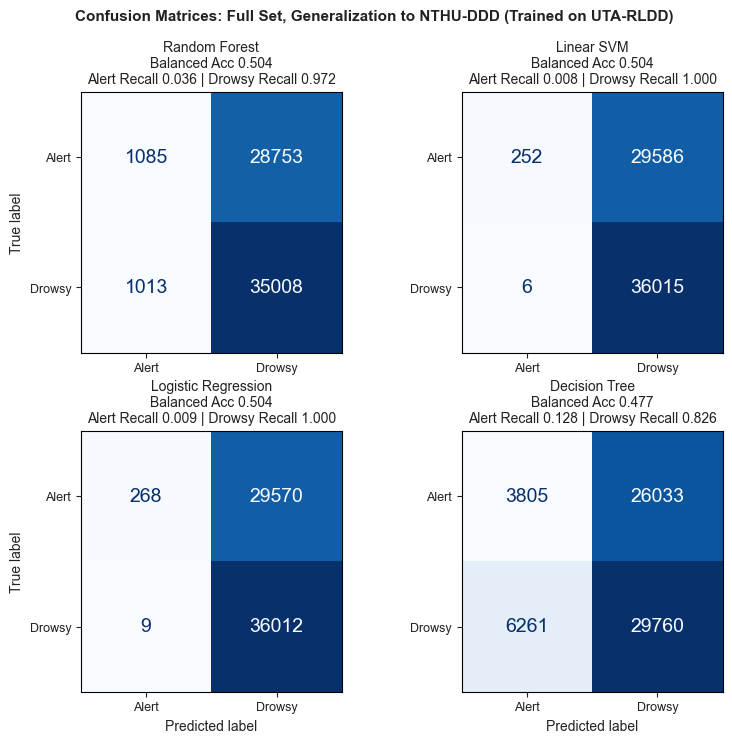

In [20]:
import os
import joblib
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             balanced_accuracy_score, recall_score, accuracy_score)

features = ['EAR', 'MAR', 'Pitch', 'Yaw', 'Roll']
model_files = {
    "Random Forest": "random_forest_full_set_model.joblib",
    "Linear SVM": "linear_svm_full_set_model.joblib",
    "Logistic Regression": "logistic_regression_full_set_model.joblib",
    "Decision Tree": "decision_tree_full_set_model.joblib",
}

def summarize(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "Drowsy Recall": recall_score(y_true, y_pred),
        "Alert Recall": recall_score(y_true, y_pred, pos_label=0),
    }

def panel_title(name, s):
    return (f"{name}\nBalanced Acc {s['Balanced Accuracy']:.3f}\n"
            f"Alert Recall {s['Alert Recall']:.3f} | Drowsy Recall {s['Drowsy Recall']:.3f}")

df_nthu = pd.read_csv(os.path.join(DATA_DIR, "nthu_complete_results_pose_fixed.csv"))
print(f"NTHU-DDD rows: {len(df_nthu)} | Drowsy share: {df_nthu['Target'].mean():.4f}")

fig, axes = plt.subplots(2, 2, figsize=(8, 7.5))
axes = axes.flatten()

for i, (ax, (name, fname)) in enumerate(zip(axes, model_files.items())):
    clf = joblib.load(os.path.join(DATA_DIR, fname))
    preds = clf.predict(df_nthu[features])
    s = summarize(df_nthu['Target'], preds)
    print(name, {k: round(v, 4) for k, v in s.items()})
    ConfusionMatrixDisplay(confusion_matrix(df_nthu['Target'], preds),
                           display_labels=['Alert', 'Drowsy']).plot(
        cmap='Blues', ax=ax, colorbar=False, values_format='d')
    ax.set_title(panel_title(name, s), fontsize=10, pad=6)
    ax.grid(False)
    ax.tick_params(axis='both', labelsize=9)
    ax.set_xlabel("Predicted label" if i >= 2 else "", fontsize=10)
    ax.set_ylabel("True label" if i % 2 == 0 else "", fontsize=10)

plt.suptitle("Confusion Matrices: Full Set, Generalization to NTHU-DDD (Trained on UTA-RLDD)",
             fontweight='bold', fontsize=11, y=0.98)
plt.subplots_adjust(left=0.09, right=0.98, top=0.87, bottom=0.07, hspace=0.30, wspace=0.15)
plt.savefig(os.path.join(DATA_DIR, "confusion_full_set_nthu_generalization.png"), dpi=300, bbox_inches="tight", pad_inches=0.05)
plt.show()

### Random Forest balanced accuracy under the three splits, bar chart
The paper reports these values as a table (section 5.1 of the main notebook).

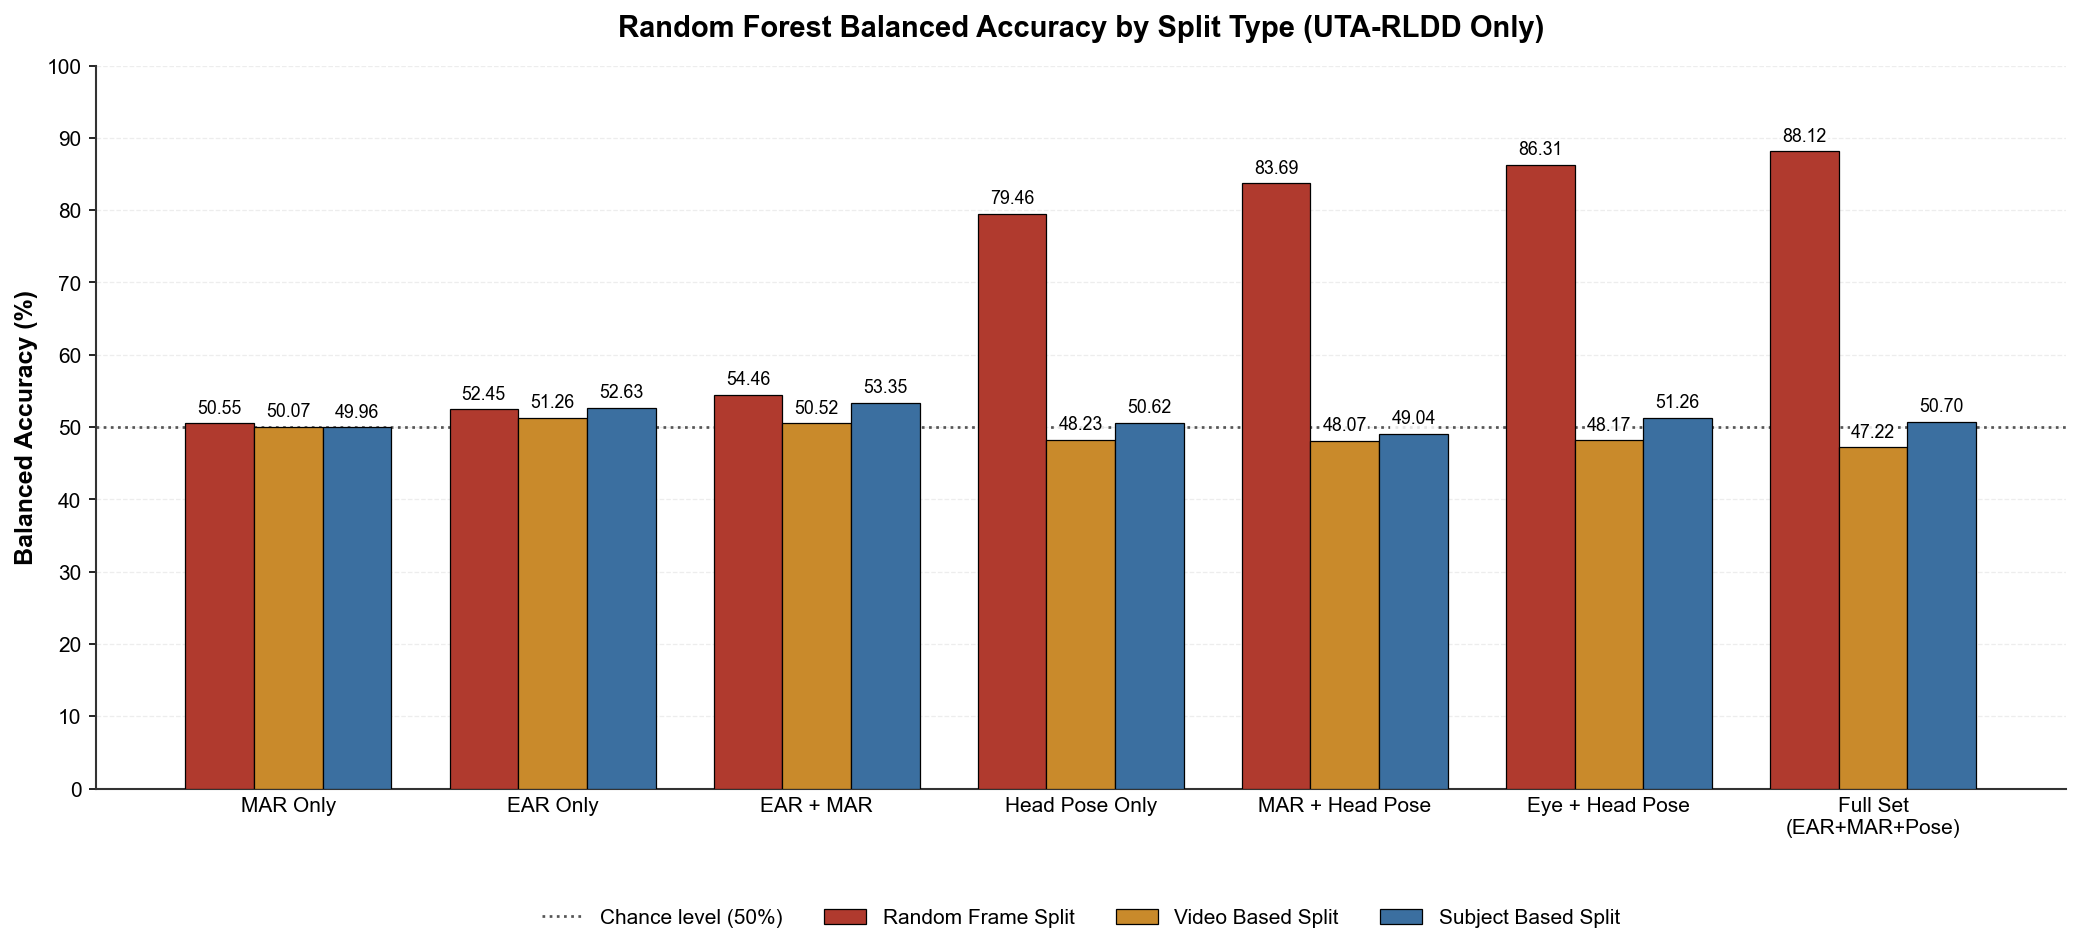

In [78]:
res = pd.read_csv(os.path.join(DATA_DIR, "rf_three_way_split_comparison.csv"))

feature_order = ["MAR Only", "EAR Only", "EAR + MAR", "Head Pose Only",
                 "MAR + Head Pose", "Eye + Head Pose", "Full Set (EAR+MAR+Pose)"]
split_order = ["Random Split", "Video-Based Split", "Subject-Based Split"]
split_labels = {
    "Random Split": "Random Frame Split",
    "Video-Based Split": "Video Based Split",
    "Subject-Based Split": "Subject Based Split",
}
split_colors = {
    "Random Split": "#B03A2E",
    "Video-Based Split": "#C98A2B",
    "Subject-Based Split": "#3B6FA0",
}
xt_labels = [f.replace("Full Set (EAR+MAR+Pose)", "Full Set\n(EAR+MAR+Pose)") for f in feature_order]

plt.rcParams.update({
    "font.family": "Arial", "font.size": 11, "axes.titlesize": 14,
    "axes.labelsize": 12, "xtick.labelsize": 10, "ytick.labelsize": 10, "legend.fontsize": 10
})

x = np.arange(len(feature_order))
width = 0.26
fig, ax = plt.subplots(figsize=(14, 6.5))

for i, split in enumerate(split_order):
    vals = [res[(res["Split Type"] == split) & (res["Feature Set"] == f)]["Balanced Accuracy"].values[0] * 100
            for f in feature_order]
    bars = ax.bar(x + (i - 1) * width, vals, width, label=split_labels[split],
                  color=split_colors[split], edgecolor="black", linewidth=0.6, zorder=3)
    # Value labels with a white background, so the chance line does not run through them.
    for t in ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=8.5):
        t.set_bbox(dict(facecolor="white", edgecolor="none", pad=0.5, alpha=0.85))

ax.axhline(50, color="#555555", linestyle=":", linewidth=1.3, zorder=2, label="Chance level (50%)")
ax.set_xticks(x)
ax.set_xticklabels(xt_labels, ha="center")
ax.set_ylabel("Balanced Accuracy (%)", fontweight="bold")
ax.set_ylim(0, 100)
ax.set_yticks(np.arange(0, 101, 10))
ax.set_title("Random Forest Balanced Accuracy by Split Type (UTA-RLDD Only)", fontweight="bold", pad=14)
ax.grid(axis="y", linestyle="--", linewidth=0.6, alpha=0.45, zorder=0)
ax.xaxis.grid(False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(axis="x", length=0)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=4, frameon=False)

plt.tight_layout()
plt.savefig(os.path.join(DATA_DIR, "three_way_split_rf.png"), dpi=300, bbox_inches="tight", facecolor="white")
plt.savefig(os.path.join(DATA_DIR, "three_way_split_rf.pdf"), bbox_inches="tight", facecolor="white")
plt.show()

## Earlier training code
These cells were not run in their final form and have no outputs.

### Bi-LSTM on held-out drivers, first version
Same architecture, data and validation drivers as the final run, but it reports only accuracy, precision, recall and F1. Replaced by section 6.1 of the main notebook, which adds balanced accuracy and per-class recall.

### Random Forest on held-out drivers, first version
Replaced by section 5.3 of the main notebook.

### All static classifiers on held-out drivers and NTHU-DDD, first version
Saved one model and one prediction file per classifier and feature set. Replaced by section 5.3 of the main notebook.